<center><h1>Loke_Eliza_HW7</h1></center>

Name: Eliza Loke
<br>
Github Username: eliza-data
<br>
USC ID: 9840375742

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [38]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score
from itertools import product
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


### (a) Download the Anuran Calls (MFCCs) Data Set

In [39]:
############ Directory setup for data files ############
NOTEBOOK_DIR = Path('.').resolve()

if NOTEBOOK_DIR.name.strip().lower() in ['notebook', 'notebooks']:
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

# Step up to the project root directory, then point to folder
DATA_DIR = PROJECT_ROOT / 'Anuran Calls (MFCCs)' 

# Set the train and test dataset files
DATA_FILE = DATA_DIR / 'Frogs_MFCCs.csv'


# Checks if the data directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found at: {DATA_DIR}\n"
        "Check 'Anuran Calls (MFCCs)' folder located in the project root folder."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Directory: {DATA_DIR}")
print(f"Dataset File: {DATA_FILE}")

Project Root: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 7 Data
Dataset Directory: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 7 Data/Anuran Calls (MFCCs)
Dataset File: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv


### (b) Train a classifier for each label

#### (i) Research

Methods for evaluating multi-label classification
Exact Match - measures the proportion of observations for which all three predicted labels are correct.
Hamming Loss - measures the proportion of individual label predictions that are incorrect across all observations.
Hamming Score - measures the proportion of individual label predictions that are correct.

#### (ii) Train a SVM for each of the labels

In [40]:
############ 1. Prepare training and test dataset ############

# Load dataset into a pandas DataFrame
data = pd.read_csv(DATA_FILE)

# Separate independent features (ind_features)
ind_features = data.drop(
    columns=['Family', 'Genus', 'Species', 'RecordID']
)

# Separate dependent targets (dep_target)
dep_target = data[['Family', 'Genus', 'Species']]

# Randomly split data into 70% training and 30% testing
ind_features_train_raw, ind_features_test_raw, dep_target_train, dep_target_test = train_test_split(
    ind_features, dep_target, test_size=0.30, random_state=565
)

# Standardize features using the training data
scaler = StandardScaler()

ind_features_train_scaled = pd.DataFrame(
    scaler.fit_transform(ind_features_train_raw), # fit_transform() calculates the mean std from training set and standardizes it.
    columns=ind_features_train_raw.columns,
    index=ind_features_train_raw.index
)

# Apply the same scaling to the test data
ind_features_test_scaled = pd.DataFrame(
    scaler.transform(ind_features_test_raw), # transform() applies those same training statistics to the test data.
    columns=ind_features_test_raw.columns,
    index=ind_features_test_raw.index
)

print(ind_features_train_scaled.head())


# Check training and testing dimensions
print("Training features:", ind_features_train_raw.shape)
print("Testing features:", ind_features_test_raw.shape)

# Check target dimensions
print("Training labels:", dep_target_train.shape)
print("Testing labels:", dep_target_test.shape)

# Check number of classes in each target
print("\nUnique classes in training labels:")
print(dep_target_train.nunique())


      MFCCs_ 1  MFCCs_ 2  MFCCs_ 3  MFCCs_ 4  MFCCs_ 5  MFCCs_ 6  MFCCs_ 7  \
1997  0.144964 -0.055674 -0.272906  0.835654  0.186515 -1.315781 -0.787720   
6     0.144964 -1.381909 -1.417773 -0.796287  1.563362  0.680361 -0.231528   
2834  0.144964  0.500078 -0.517968  1.310479  0.648725 -1.206349 -0.890626   
2129  0.144964 -0.893594 -0.545289  0.507340 -0.319697 -0.805460 -0.540165   
5930  0.144964 -0.939982  0.156226 -0.574346  0.179036  0.974895  0.639453   

      MFCCs_ 8  MFCCs_ 9  MFCCs_10  ...  MFCCs_13  MFCCs_14  MFCCs_15  \
1997  0.828498  0.807284 -0.464277  ...  1.134340 -0.682205 -1.174319   
6    -2.182882 -1.644584  1.291447  ... -1.849615  0.435325  1.684226   
2834  0.800473  0.751682 -0.118904  ...  1.287383  0.846460 -1.116566   
2129  0.700994  0.580132 -0.746799  ...  0.964073 -0.762173 -0.575341   
5930 -1.407315 -0.987733  0.286371  ... -0.324983 -0.177194  0.041687   

      MFCCs_16  MFCCs_17  MFCCs_18  MFCCs_19  MFCCs_20  MFCCs_21  MFCCs_22  
1997  0.528812 

In [41]:
############ 2. Determine initial SVM parameter ranges ############

# Initial parameter values
C_values = [0.001, 1, 1000, 1000000]
sigma_values = [0.1, 0.5, 1.0, 2.0]

# Select Family as the target (only use Family to test the comnibination of C and sigma)
family_train = dep_target_train['Family']

# Test every combination of C and sigma
results = []

for C, sigma in product(C_values, sigma_values):

    # Convert Gaussian width (sigma) into sklearn's gamma
    gamma = 1 / (2 * sigma**2)

    # Create One-vs-All Gaussian SVM (Machine Learning Model)
    svm_model = OneVsRestClassifier(        # OneVsRestClassifier(...) (wraps the SVM inside the One-vs-Rest strategy) 
        SVC(kernel='rbf', C=C, gamma=gamma) # creates an SVM classifier (creates four binary classifiers for the four Family classes)
    )                                       # kernel='rbf'	(Use a Gaussian Radial Basis Function kernel)
                                            # C=C	(Use the current penalty value from loop)
                                            # gamma=gamma   (Use the gamma calculated from sigma)

    # Train the model
    svm_model.fit(ind_features_train_raw, family_train)

    # Calculate training accuracy
    predictions = svm_model.predict(ind_features_train_raw)
    accuracy = accuracy_score(family_train, predictions)

    # Store results
    results.append({
        'C': C,
        'Sigma': sigma,
        'Training Accuracy': accuracy
    })

# Display results
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))



############ Check training accuracy threshold ############
# Set the minimum acceptable training accuracy
threshold = 0.70

# Identify parameter combinations meeting the threshold
acceptable_results = results_df[
    results_df['Training Accuracy'] >= threshold
]

# Display the conclusion
if not acceptable_results.empty:
    print(f"Parameter combinations meeting the {threshold:.0%} threshold:")
    print(acceptable_results.to_string(index=False))
else:
    print(f"No parameter combinations meet the {threshold:.0%} threshold.")


          C  Sigma  Training Accuracy
      0.001    0.1           0.608221
      0.001    0.5           0.608221
      0.001    1.0           0.608221
      0.001    2.0           0.608221
      1.000    0.1           1.000000
      1.000    0.5           0.995234
      1.000    1.0           0.973590
      1.000    2.0           0.947975
   1000.000    0.1           1.000000
   1000.000    0.5           1.000000
   1000.000    1.0           1.000000
   1000.000    2.0           0.998610
1000000.000    0.1           1.000000
1000000.000    0.5           1.000000
1000000.000    1.0           1.000000
1000000.000    2.0           1.000000
Parameter combinations meeting the 70% threshold:
        C  Sigma  Training Accuracy
      1.0    0.1           1.000000
      1.0    0.5           0.995234
      1.0    1.0           0.973590
      1.0    2.0           0.947975
   1000.0    0.1           1.000000
   1000.0    0.5           1.000000
   1000.0    1.0           1.000000
   1000.0    2.0

### (ii) Raw Attributes : 10-fold cross-validation 

In [42]:
############ 3. Perform 10-fold cross-validation for all three classes using raw attributes ############

# Convert sigma values into gamma values for Scikit-learn
gamma_values = 1 / (2 * np.square(sigma_values))

# Define the parameter grid
param_grid = {
    'estimator__C': C_values,
    'estimator__gamma': gamma_values
}

# Set up 10-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=565
)

In [43]:
############ 4.Family: 10-fold cross-validation (raw) ############

# Create the One-vs-Rest Gaussian SVM
family_svm = OneVsRestClassifier(
    SVC(kernel='rbf')
)

# Search for the best parameter combination
family_grid_search_raw = GridSearchCV(
    estimator=family_svm,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv_strategy,
    n_jobs=4,
    verbose=1
)

# Train and evaluate parameter combinations
family_grid_search_raw.fit(
    ind_features_train_raw,
    dep_target_train['Family']
)

# Retrieve the best parameters
best_C = family_grid_search_raw.best_params_['estimator__C']
best_gamma = family_grid_search_raw.best_params_['estimator__gamma']
best_sigma = np.sqrt(1 / (2 * best_gamma))

# Display the best results
print("Best C:", best_C)
print("Best Sigma:", best_sigma)
print("Best 10-fold CV Accuracy:", family_grid_search_raw.best_score_)

Fitting 10 folds for each of 16 candidates, totalling 160 fits
Best C: 1000
Best Sigma: 0.5
Best 10-fold CV Accuracy: 0.9936468490643442


In [44]:
############ 5. Genus: 10-fold cross-validation (raw) ############

genus_svm = OneVsRestClassifier(SVC(kernel='rbf'))

genus_grid_search_raw = GridSearchCV(
    estimator=genus_svm,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv_strategy,
    n_jobs=4,
    verbose=1
)

genus_grid_search_raw.fit(
    ind_features_train_raw,
    dep_target_train['Genus']
)

best_C_genus = genus_grid_search_raw.best_params_['estimator__C']
best_gamma_genus = genus_grid_search_raw.best_params_['estimator__gamma']
best_sigma_genus = np.sqrt(1 / (2 * best_gamma_genus))

print("Best C:", best_C_genus)
print("Best Sigma:", best_sigma_genus)
print("Best 10-fold CV Accuracy:", genus_grid_search_raw.best_score_)

Fitting 10 folds for each of 16 candidates, totalling 160 fits
Best C: 1000
Best Sigma: 0.5
Best 10-fold CV Accuracy: 0.9900722648237558


In [45]:
############ 6. Species: 10-fold cross-validation (raw) ############

species_svm = OneVsRestClassifier(SVC(kernel='rbf'))

species_grid_search_raw = GridSearchCV(
    estimator=species_svm,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv_strategy,
    n_jobs=4,
    verbose=1
)

species_grid_search_raw.fit(
    ind_features_train_raw,
    dep_target_train['Species']
)

best_C_species = species_grid_search_raw.best_params_['estimator__C']
best_gamma_species = species_grid_search_raw.best_params_['estimator__gamma']
best_sigma_species = np.sqrt(1 / (2 * best_gamma_species))

print("Best C:", best_C_species)
print("Best Sigma:", best_sigma_species)
print("Best 10-fold CV Accuracy:", species_grid_search_raw.best_score_)

Fitting 10 folds for each of 16 candidates, totalling 160 fits
Best C: 1000
Best Sigma: 0.5
Best 10-fold CV Accuracy: 0.990668686294929


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [46]:
############ 1. Standardize MFCC features for L1 SVM ############

# Initialize the scaler
scaler_l1 = StandardScaler() # initializes the standardization process

# Fit and transform training features
ind_features_train_l1_scaled = pd.DataFrame(
    scaler_l1.fit_transform(ind_features_train_raw), # calculates training feature means and std, then standardizes training data
    columns=ind_features_train_raw.columns,
    index=ind_features_train_raw.index
)

# Transform test features using the training scaler
ind_features_test_l1_scaled = pd.DataFrame(
    scaler_l1.transform(ind_features_test_raw), # applies those same training statistics to the test data
    columns=ind_features_test_raw.columns,
    index=ind_features_test_raw.index
)

# Verify standardized training features
print("Training feature means:")
print(ind_features_train_l1_scaled.mean().round(4))

print("\nTraining feature standard deviations:")
print(ind_features_train_l1_scaled.std().round(4))

Training feature means:
MFCCs_ 1    0.0
MFCCs_ 2    0.0
MFCCs_ 3   -0.0
MFCCs_ 4   -0.0
MFCCs_ 5    0.0
MFCCs_ 6    0.0
MFCCs_ 7    0.0
MFCCs_ 8    0.0
MFCCs_ 9    0.0
MFCCs_10    0.0
MFCCs_11    0.0
MFCCs_12    0.0
MFCCs_13   -0.0
MFCCs_14    0.0
MFCCs_15    0.0
MFCCs_16    0.0
MFCCs_17   -0.0
MFCCs_18   -0.0
MFCCs_19   -0.0
MFCCs_20   -0.0
MFCCs_21    0.0
MFCCs_22    0.0
dtype: float64

Training feature standard deviations:
MFCCs_ 1    1.0001
MFCCs_ 2    1.0001
MFCCs_ 3    1.0001
MFCCs_ 4    1.0001
MFCCs_ 5    1.0001
MFCCs_ 6    1.0001
MFCCs_ 7    1.0001
MFCCs_ 8    1.0001
MFCCs_ 9    1.0001
MFCCs_10    1.0001
MFCCs_11    1.0001
MFCCs_12    1.0001
MFCCs_13    1.0001
MFCCs_14    1.0001
MFCCs_15    1.0001
MFCCs_16    1.0001
MFCCs_17    1.0001
MFCCs_18    1.0001
MFCCs_19    1.0001
MFCCs_20    1.0001
MFCCs_21    1.0001
MFCCs_22    1.0001
dtype: float64


In [47]:
############ 2. Set up L1-penalized linear SVM ############

# Define candidate penalty values (C) using logarithmic increments
C_values_l1 = [0.001, 0.01, 0.1, 1, 10, 100, 1000] # C_values_l1: Tests seven penalty values, spaced logarithmically

# Set up 10-fold stratified cross-validation
cv_strategy_l1 = StratifiedKFold( #StratifiedKFold: Divides training data into 10 folds, maintains class proportions
    n_splits=10,
    shuffle=True,
    random_state=565
)

# Create L1-penalized linear SVM
l1_svm = OneVsRestClassifier( #OneVsRestClassifier: Trains a separate classifier for each class within each target
    LinearSVC( #LinearSVC(penalty='l1', dual=False): Uses a linear SVM with L1 regularization
        penalty='l1', 
        dual=False, 
        max_iter=20000,
        random_state=565
        ) 
)

# Define the parameter grid
param_grid_l1 = { #param_grid_l1: Tells cross-validation to determine the best C
    'estimator__C': C_values_l1
}

In [48]:
############ 3. L1 SVM penalty (Family) ############

# Set up grid search
family_grid_search_l1 = GridSearchCV( # GridSearchCV: Tests different parameter values using cross-validation
    estimator=l1_svm, # estimator=l1_svm: Uses the L1-penalized linear SVM 
    param_grid=param_grid_l1, # param_grid=param_grid_l1: Tests the seven candidate C values: 0.001 through 1000
    scoring='accuracy', # scoring='accuracy': Evaluates each candidate using classification accuracy
    cv=cv_strategy_l1, # cv=cv_strategy_l1: Uses previously defined 10-fold stratified cross-validation
    n_jobs=4, # n_jobs=1: Runs one job at a time to limit computational load
    verbose=1 # verbose=1: Displays progress while the search runs
)

# Train and perform 10-fold cross-validation
family_grid_search_l1.fit( # .fit(): Trains and evaluates the SVM using each candidate C value across the 10 folds
    ind_features_train_l1_scaled, # standardized MFCC training features
    dep_target_train['Family'] # Family labels that the model is learning to predict
)

# Display results
print("Best C for Family:", family_grid_search_l1.best_params_['estimator__C'])
print("Best 10-fold CV Accuracy for Family:", family_grid_search_l1.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Family: 10
Best 10-fold CV Accuracy for Family: 0.9384419672441542


In [49]:
############ 4. L1 SVM penalty (Genus) ############

# Set up grid search
genus_grid_search_l1 = GridSearchCV(
    estimator=l1_svm,
    param_grid=param_grid_l1,
    scoring='accuracy',
    cv=cv_strategy_l1,
    n_jobs=4,
    verbose=1
)

# Train and perform 10-fold cross-validation
genus_grid_search_l1.fit(
    ind_features_train_l1_scaled,
    dep_target_train['Genus']
)

# Display results
print("Best C for Genus:", genus_grid_search_l1.best_params_['estimator__C'])
print("Best 10-fold CV Accuracy for Genus:", genus_grid_search_l1.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Genus: 10
Best 10-fold CV Accuracy for Genus: 0.9557220171037267


In [50]:
############ 5. Tune L1 SVM penalty for Species ############
species_grid_search_l1 = GridSearchCV(
    estimator=l1_svm,
    param_grid=param_grid_l1,
    scoring='accuracy',
    cv=cv_strategy_l1,
    n_jobs=4,
    verbose=1
)

species_grid_search_l1.fit(
    ind_features_train_l1_scaled,
    dep_target_train['Species']
)

print("Best C for Species:", species_grid_search_l1.best_params_['estimator__C'])
print("Best 10-fold CV Accuracy for Species:", species_grid_search_l1.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Species: 1
Best 10-fold CV Accuracy for Species: 0.9650525418915082


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [51]:
############ 1. Set up SMOTE for L1 SVM ############

# Create a pipeline containing SMOTE and the L1 linear SVM
l1_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=565)),
    ('svm', OneVsRestClassifier(
        LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=300000,
            random_state=565
        ),
        n_jobs=4  
    ))
])

# Set up the C values to test
C_values_smote = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

# Set up the parameter grid
param_grid_smote = {
    'svm__estimator__C': C_values_smote
}

print("SMOTE pipeline is in check.")

SMOTE pipeline is in check.


In [52]:
############ 2. L1 SVM penalty for Family (SMOTE) ############

family_grid_search_smote = GridSearchCV(
    estimator=l1_smote_pipeline,
    param_grid=param_grid_smote,
    scoring='accuracy',
    cv=cv_strategy_l1,
    n_jobs=4,
    verbose=1
)

family_grid_search_smote.fit(
    ind_features_train_l1_scaled,
    dep_target_train['Family']
)

print("Best C for Family with SMOTE:",
      family_grid_search_smote.best_params_['svm__estimator__C'])

print("Best 10-fold CV Accuracy for Family with SMOTE:",
      family_grid_search_smote.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Family with SMOTE: 1
Best 10-fold CV Accuracy for Family with SMOTE: 0.9237515383887154


In [53]:
############ 3. L1 SVM penalty for Genus (SMOTE) ############

genus_grid_search_smote = GridSearchCV(
    estimator=l1_smote_pipeline,
    param_grid=param_grid_smote,
    scoring='accuracy',
    cv=cv_strategy_l1,
    n_jobs=4,
    verbose=1
)

genus_grid_search_smote.fit(
    ind_features_train_l1_scaled,
    dep_target_train['Genus']
)

print("Best C for Genus with SMOTE:",
      genus_grid_search_smote.best_params_['svm__estimator__C'])

print("Best 10-fold CV Accuracy for Genus with SMOTE:",
      genus_grid_search_smote.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Genus with SMOTE: 10
Best 10-fold CV Accuracy for Genus with SMOTE: 0.9205761462968223


In [54]:
############ 4. L1 SVM penalty for Species (SMOTE) ############

species_grid_search_smote = GridSearchCV(
    estimator=l1_smote_pipeline,
    param_grid=param_grid_smote,
    scoring='accuracy',
    cv=cv_strategy_l1,
    n_jobs=4,
    verbose=1
)

species_grid_search_smote.fit(
    ind_features_train_l1_scaled,
    dep_target_train['Species']
)

print("Best C for Species with SMOTE:",
      species_grid_search_smote.best_params_['svm__estimator__C'])

print("Best 10-fold CV Accuracy for Species with SMOTE:",
      species_grid_search_smote.best_score_)

Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best C for Species with SMOTE: 100
Best 10-fold CV Accuracy for Species with SMOTE: 0.963861671242387


In [55]:
############ 5. Compare L1 SVM results with and without SMOTE ############

comparison_results = pd.DataFrame({
    'Target': ['Family', 'Genus', 'Species'],

    'Best C (No SMOTE)': [
        family_grid_search_l1.best_params_['estimator__C'],
        genus_grid_search_l1.best_params_['estimator__C'],
        species_grid_search_l1.best_params_['estimator__C']
    ],

    'CV Accuracy (No SMOTE)': [
        family_grid_search_l1.best_score_,
        genus_grid_search_l1.best_score_,
        species_grid_search_l1.best_score_
    ],

    'Best C (SMOTE)': [
        family_grid_search_smote.best_params_['svm__estimator__C'],
        genus_grid_search_smote.best_params_['svm__estimator__C'],
        species_grid_search_smote.best_params_['svm__estimator__C']
    ],

    'CV Accuracy (SMOTE)': [
        family_grid_search_smote.best_score_,
        genus_grid_search_smote.best_score_,
        species_grid_search_smote.best_score_
    ]
})

comparison_results['Accuracy Difference (%)'] = (
    comparison_results['CV Accuracy (SMOTE)'] -
    comparison_results['CV Accuracy (No SMOTE)']
) * 100

print(comparison_results.round(4).to_string(index=False))

 Target  Best C (No SMOTE)  CV Accuracy (No SMOTE)  Best C (SMOTE)  CV Accuracy (SMOTE)  Accuracy Difference (%)
 Family                 10                  0.9384               1               0.9238                  -1.4690
  Genus                 10                  0.9557              10               0.9206                  -3.5146
Species                  1                  0.9651             100               0.9639                  -0.1191


### (iv) Report on L1 SVM results with and without SMOTE

SMOTE was used to resolve the class imbalance while training three of the L1-penalized linear SVM classifiers. The 10-fold cross-validation was applied to find the penalty parameter C. The following comparison focusses on the accuracy results across all three classifiers trained without SMOTE. Family accuracy decreased by 1.4690%, while Genus improved by 0.8140%, and Species had a slight decrease of -0.0992. Overall, SMOTE demonstrated improvements for Genus, but not for Family and Species. These results show accuracy to be dependent on the target classifiers and SMOTE effectiveness to be inconsistent. 

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [56]:
############ 1. Prepare Dataset ############

# Separate independent variables the 22 MFCC features (int_target)
ind_features = data.drop(
    columns=['Family', 'Genus', 'Species', 'RecordID']
)

# Separate dependent targets (dep_target)
dep_target = data[['Family', 'Genus', 'Species']]

# Check dataset dimensions
print("Feature dimensions:", ind_features.shape)
print("Target dimensions:", dep_target.shape)

# Check feature and target columns
print("\nFeature columns:")
print(ind_features.columns.tolist())

print("\nTarget columns:")
print(dep_target.columns.tolist())


Feature dimensions: (7195, 22)
Target dimensions: (7195, 3)

Feature columns:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22']

Target columns:
['Family', 'Genus', 'Species']


In [57]:
############ 2. Standardize the 22 MFCC Independt Features ############

scaler_kmeans = StandardScaler() #standardization tool

ind_features_scaled = pd.DataFrame(
    scaler_kmeans.fit_transform(ind_features), # fit_transform(ind_features) calculates mean and std of each feature (standardizes the dataset)
    columns=ind_features.columns,
    index=ind_features.index
)

# Verify standardization
print("Feature means (first 5):")
print(ind_features_scaled.mean().head())

print("\nFeature standard deviations (first 5):")
print(ind_features_scaled.std().head())

Feature means (first 5):
MFCCs_ 1   -3.476178e-16
MFCCs_ 2    1.580081e-16
MFCCs_ 3   -3.160162e-17
MFCCs_ 4   -3.318170e-16
MFCCs_ 5   -9.480487e-17
dtype: float64

Feature standard deviations (first 5):
MFCCs_ 1    1.000069
MFCCs_ 2    1.000069
MFCCs_ 3    1.000069
MFCCs_ 4    1.000069
MFCCs_ 5    1.000069
dtype: float64


In [58]:
############ 3. Select Optimal k ############

# Random sample for silhouette calculation
ind_features_sample = ind_features_scaled.sample(
    n=2000, #use a random sample of 2,000 to estimate Silhouette score (entire datset: 7,195 observations), while fitting K-means on entire dataset
    random_state=565
)

silhouette_scores = []

# Test k values from 2 to 50
for k in range(2, 51): #start at k = 2 since Silhouette score cannot be calculated with only one cluster

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=565
    )

    cluster_labels = kmeans.fit_predict(ind_features_scaled) #fit_predict(ind_features_scaled) to fit K-means on the entire dataset and obtain cluster assignments

    # Calculate silhouette score using the sample
    score = silhouette_score( #silhouette_score() to evaluate the clustering using a sample of 2,000 observations.
        ind_features_sample,
        kmeans.predict(ind_features_sample)
    )

    silhouette_scores.append(score)

    print(f"k = {k}, Silhouette Score = {score:.4f}")

# Identify the best k-value of clusters
best_k = range(2, 51)[np.argmax(silhouette_scores)]

print("\nOptimal number of clusters:", best_k)
print("Highest Silhouette Score:", max(silhouette_scores))

k = 2, Silhouette Score = 0.3330
k = 3, Silhouette Score = 0.3583
k = 4, Silhouette Score = 0.3598
k = 5, Silhouette Score = 0.3596
k = 6, Silhouette Score = 0.2751
k = 7, Silhouette Score = 0.2832
k = 8, Silhouette Score = 0.2891
k = 9, Silhouette Score = 0.2933
k = 10, Silhouette Score = 0.2830
k = 11, Silhouette Score = 0.2490
k = 12, Silhouette Score = 0.2434
k = 13, Silhouette Score = 0.2338
k = 14, Silhouette Score = 0.2499
k = 15, Silhouette Score = 0.2410
k = 16, Silhouette Score = 0.2382
k = 17, Silhouette Score = 0.2425
k = 18, Silhouette Score = 0.2367
k = 19, Silhouette Score = 0.2506
k = 20, Silhouette Score = 0.2345
k = 21, Silhouette Score = 0.2456
k = 22, Silhouette Score = 0.2441
k = 23, Silhouette Score = 0.2365
k = 24, Silhouette Score = 0.2407
k = 25, Silhouette Score = 0.2338
k = 26, Silhouette Score = 0.2425
k = 27, Silhouette Score = 0.2296
k = 28, Silhouette Score = 0.2209
k = 29, Silhouette Score = 0.2367
k = 30, Silhouette Score = 0.2170
k = 31, Silhouette Sco

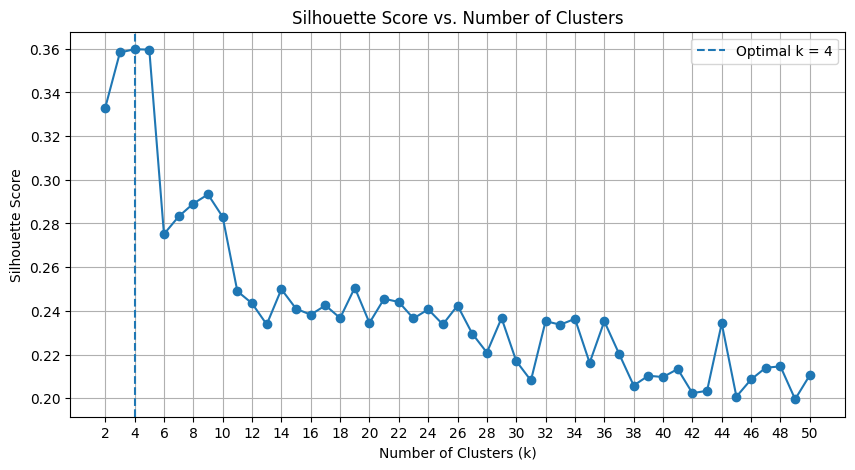

Selected number of clusters: 4


In [59]:
############ 4. Plot Silhouette Scores ############

plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 51),
    silhouette_scores,
    marker='o'
)

plt.axvline(
    x=best_k,
    linestyle='--',
    label=f'Optimal k = {best_k}'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.xticks(range(2, 51, 2))
plt.legend()
plt.grid(True)

plt.show()

print("Selected number of clusters:", best_k)

In [60]:
############ 5. Fit K-Means ############

kmeans_final = KMeans(
    n_clusters=best_k, #n_clusters=best_k: Assigns all 7,195 observations to four clusters using the Silhouette method 
    n_init=10, #n_init=10: Runs K-means with 10 different initial centroid configurations and keeps the best result
    random_state=565
)

cluster_assignments = kmeans_final.fit_predict(ind_features_scaled) #fit_predict(): Fits K-means to entire dataset and returns cluster_assignment for each observation

# Display the number of observations assigned to each cluster
print("Cluster sizes:")
print(pd.Series(cluster_assignments).value_counts().sort_index())

Cluster sizes:
0     671
1     606
2    3553
3    2365
Name: count, dtype: int64


### (b) Determine which family is the majority

In [61]:
############ 1. Combine Clusters with True Labels ############

cluster_results = dep_target.copy()
cluster_results['Cluster'] = cluster_assignments #adds the cluster number assigned by K-means to each observation

print(cluster_results.head())

            Family      Genus         Species  Cluster
0  Leptodactylidae  Adenomera  AdenomeraAndre        0
1  Leptodactylidae  Adenomera  AdenomeraAndre        0
2  Leptodactylidae  Adenomera  AdenomeraAndre        0
3  Leptodactylidae  Adenomera  AdenomeraAndre        0
4  Leptodactylidae  Adenomera  AdenomeraAndre        0


In [62]:
############ 2. Determine Majority Labels ############

majority_labels = cluster_results.groupby('Cluster')[ #groupby('Cluster') separates the observations into the four clusters
    ['Family', 'Genus', 'Species']
].agg(lambda column: column.mode().iloc[0]) #.iloc[0] selects the first mode if there is a tie.

print("Majority labels for each cluster:")
print(majority_labels)

Majority labels for each cluster:
                  Family      Genus                 Species
Cluster                                                    
0        Leptodactylidae  Adenomera          AdenomeraAndre
1                Hylidae  Hypsiboas    HypsiboasCinerascens
2        Leptodactylidae  Adenomera  AdenomeraHylaedactylus
3                Hylidae  Hypsiboas       HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [63]:
############ 1. Assign Majority Labels ############

cluster_predicted_labels = pd.DataFrame(
    {'Cluster': cluster_assignments},
    index=dep_target.index
)

for column in ['Family', 'Genus', 'Species']:
    cluster_predicted_labels[column] = (
        cluster_predicted_labels['Cluster'].map(majority_labels[column]) #.map(majority_labels[column]) looks up the majority label corresponding to that cluster.
    )

cluster_predicted_labels = cluster_predicted_labels[
    ['Family', 'Genus', 'Species']
]

print("Predicted labels:")
print(cluster_predicted_labels.head())

Predicted labels:
            Family      Genus         Species
0  Leptodactylidae  Adenomera  AdenomeraAndre
1  Leptodactylidae  Adenomera  AdenomeraAndre
2  Leptodactylidae  Adenomera  AdenomeraAndre
3  Leptodactylidae  Adenomera  AdenomeraAndre
4  Leptodactylidae  Adenomera  AdenomeraAndre


In [64]:
############ 2. Identify Incorrect Predictions ############

incorrect_predictions = dep_target.ne(cluster_predicted_labels) #Compare predicted labels with the actual labels

print("Incorrect predictions (True = incorrect):")
print(incorrect_predictions.head())

Incorrect predictions (True = incorrect):
   Family  Genus  Species
0   False  False    False
1   False  False    False
2   False  False    False
3   False  False    False
4   False  False    False


In [65]:
############ 3. Calculate average Hamming distance, Hamming score, and Hamming loss between true labels and labels assigned by clusters ############

hamming_distance = incorrect_predictions.sum(axis=1).mean() #Counts the number of incorrect labels per observation (0–3), then averages those counts across all observations 

hamming_loss_value = incorrect_predictions.sum().sum() / ( #total number of incorrect individual labels by the total number of possible labels (7,195 × 3)
    len(dep_target) * 3
)

hamming_score = 1 - hamming_loss_value #Subtracts Hamming Loss from 1

print(f"Average Hamming Distance: {hamming_distance:.4f}")
print(f"Hamming Score: {hamming_score:.4f}")
print(f"Hamming Loss: {hamming_loss_value:.4f}")

Average Hamming Distance: 0.7426
Hamming Score: 0.7525
Hamming Loss: 0.2475


In [66]:
############ 4. 50 Monte Carlo Repetitions ############

hamming_distances = [] #hamming_distances stores Hamming Distance from each of the 50 runs

for run in range(50):

    # Fit K-means
    kmeans = KMeans(
        n_clusters=best_k,
        n_init=10,
        random_state=run
    )

    cluster_assignments = kmeans.fit_predict(ind_features_scaled)

    # Combine cluster assignments with true labels
    cluster_results = dep_target.copy()
    cluster_results['Cluster'] = cluster_assignments

    # Find majority labels in each cluster
    majority_labels = cluster_results.groupby('Cluster')[
        ['Family', 'Genus', 'Species']
    ].agg(lambda column: column.mode().iloc[0])

    # Assign majority labels to each observation
    cluster_predicted_labels = pd.DataFrame(
        {'Cluster': cluster_assignments},
        index=dep_target.index
    )

    for column in ['Family', 'Genus', 'Species']:
        cluster_predicted_labels[column] = (
            cluster_predicted_labels['Cluster'].map(majority_labels[column])
        )

    # Calculate average Hamming Distance
    incorrect_predictions = dep_target.ne(
        cluster_predicted_labels[['Family', 'Genus', 'Species']]
    )

    hamming_distance = incorrect_predictions.sum(axis=1).mean()
    hamming_distances.append(hamming_distance)

# Calculate summary statistics
print("Number of repetitions:", len(hamming_distances))
print(f"Average Hamming Distance: {np.mean(hamming_distances):.4f}")
print(f"Standard Deviation: {np.std(hamming_distances, ddof=1):.4f}")

Number of repetitions: 50
Average Hamming Distance: 0.7344
Standard Deviation: 0.0356


## 3. ISLR 12.6.2